# Convert and Optimize FastReID person re-identification with OpenVINO™

Person re-identification (ReID) answers the question "have I seen this person before?". A ReID network turns a cropped image of a person into a vector of numbers, an *embedding*, so that crops of the same person end up close together and crops of different people end up far apart. Embeddings are used to search a gallery of people across cameras and to keep object IDs stable in multi-object trackers such as BoT-SORT.

[FastReID](https://github.com/JDAI-CV/fast-reid) is an open-source ReID toolbox. This tutorial uses one of its trained models, **SBS-R50** (a ResNet-50 with non-local blocks, GeM pooling and a batch-norm neck, trained on [Market-1501](https://zheng-lab.cecs.anu.edu.au/Project/project_reid.html)), and shows how to run and optimize it with OpenVINO. The model takes a person crop of `384x128` pixels and returns a 2048-dimensional embedding.

The tutorial consists of the following steps:

- Prepare the PyTorch model.
- Convert the PyTorch model to OpenVINO IR (FP32, then FP16).
- Verify OpenVINO inference against PyTorch.
- Prepare and run the optimization pipeline (INT8 post-training quantization with NNCF).
- Compare the performance of the FP32, FP16 and INT8 models.



#### Table of contents:

- [Get PyTorch model](#Get-PyTorch-model)
    - [Prerequisites](#Prerequisites)
- [Instantiate model](#Instantiate-model)
    - [Prepare input data](#Prepare-input-data)
    - [Run PyTorch inference](#Run-PyTorch-inference)
    - [Convert model to OpenVINO IR](#Convert-model-to-OpenVINO-IR)
    - [Select inference device](#Select-inference-device)
    - [Verify model inference](#Verify-model-inference)
    - [Use the embeddings](#Use-the-embeddings)
- [Optimize model using NNCF Post-training Quantization API](#Optimize-model-using-NNCF-Post-training-Quantization-API)
    - [Validate Quantized model inference](#Validate-Quantized-model-inference)
- [Compare Performance of the Models](#Compare-Performance-of-the-Models)
    - [Compare performance of the FP32, FP16 and INT8 models](#Compare-performance-of-the-FP32,-FP16-and-INT8-models)


### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/fast-reid/fast-reid.ipynb" />


## Get PyTorch model
[back to top ⬆️](#Table-of-contents:)

[FastReID](https://github.com/JDAI-CV/fast-reid) ships the model code and a model zoo of trained checkpoints. This notebook downloads the repository (pinned to the version it was tested with) and the `market_sbs_R50.pth` checkpoint from the model zoo.

#### Prerequisites
[back to top ⬆️](#Table-of-contents:)

Install necessary packages.

In [1]:
%pip install -q "openvino>=2025.1.0" "nncf>=2.16.0"
%pip install -q "torch>=2.1" torchvision yacs termcolor pyyaml tqdm pillow opencv-python matplotlib --extra-index-url https://download.pytorch.org/whl/cpu


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Import required utility functions.
The lower cell will download the `notebook_utils` Python module from GitHub.

In [2]:
from pathlib import Path
import requests

if not Path("notebook_utils.py").exists():
    r = requests.get(
        url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/notebook_utils.py",
    )

    open("notebook_utils.py", "w").write(r.text)

from notebook_utils import download_file, device_widget, quantization_widget

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("fast-reid.ipynb")

Download the FastReID code and the Market-1501 SBS-R50 checkpoint. The checkpoint is an official release file of the FastReID model zoo.

In [3]:
import sys
import zipfile

MODEL_DIR = Path("model")
FASTREID_DIR = MODEL_DIR / "fast-reid"
FASTREID_COMMIT = "c9bc3ceb2f7a6438b62fb515ea3df6d1e999e95d"  # the version this notebook was tested with
WEIGHTS_PATH = MODEL_DIR / "market_sbs_R50.pth"

if not FASTREID_DIR.exists():
    archive_path = download_file(
        url=f"https://github.com/JDAI-CV/fast-reid/archive/{FASTREID_COMMIT}.zip",
        filename="fast-reid.zip",
        directory=MODEL_DIR,
    )
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(path=MODEL_DIR)
    (MODEL_DIR / f"fast-reid-{FASTREID_COMMIT}").rename(FASTREID_DIR)

if not WEIGHTS_PATH.exists():
    download_file(
        url="https://github.com/JDAI-CV/fast-reid/releases/download/v0.1.1/market_sbs_R50.pth",
        filename=WEIGHTS_PATH.name,
        directory=WEIGHTS_PATH.parent,
    )

sys.path.insert(0, str(FASTREID_DIR))

fast-reid.zip: 0.00B [00:00, ?B/s]

market_sbs_R50.pth:   0%|          | 0.00/287M [00:00<?, ?B/s]

## Instantiate model
[back to top ⬆️](#Table-of-contents:)

FastReID builds a model from a config file. `sbs_R50.yml` describes the model used here: input size `384x128` (height x width), batch-norm neck and GeM pooling. Three details matter for conversion:

- **Input:** raw `0..255` RGB, NCHW, `[B, 3, 384, 128]`. The mean/std normalization is *inside* the network, so the input must **not** be normalized again.
- **Output:** `[B, 2048]` embeddings that are *not* L2-normalized. Normalize them before comparing with cosine similarity.
- **Checkpoint keys:** the 2020 checkpoint names the head `heads.bnneck` and `heads.classifier`, the current code `heads.bottleneck.0` and `heads.weight`. The keys are renamed below and the cell fails unless **every** key loads, because a partial load would silently give wrong embeddings.

FastReID normalizes its input in place, which would modify a NumPy array shared with the caller, so the normalization is replaced by an equivalent out-of-place version.

In [4]:
import types

import numpy as np
import torch
from fastreid.config import get_cfg
from fastreid.modeling.meta_arch import build_model

cfg = get_cfg()
cfg.merge_from_file(str(FASTREID_DIR / "configs/Market1501/sbs_R50.yml"))
cfg.MODEL.BACKBONE.PRETRAIN = False  # the weights come from the checkpoint
cfg.MODEL.DEVICE = "cpu"
cfg.MODEL.HEADS.NUM_CLASSES = 751  # Market-1501 identities, needed so that the (training-only) classifier key loads

INPUT_HW = tuple(cfg.INPUT.SIZE_TEST)  # (384, 128)
BATCH = 8  # the IR is converted for a fixed batch of 8 crops
pt_model = build_model(cfg).eval()

checkpoint = torch.load(WEIGHTS_PATH, map_location="cpu", weights_only=False)["model"]  # official release file
state = {k.replace("heads.bnneck.", "heads.bottleneck.0.").replace("heads.classifier.weight", "heads.weight"): v for k, v in checkpoint.items()}
result = pt_model.load_state_dict(state, strict=False)
unexpected = [k for k in result.unexpected_keys if k not in ("pixel_mean", "pixel_std")]
assert not result.missing_keys and not unexpected, f"checkpoint does not match the model: {result.missing_keys[:3]} {unexpected[:3]}"


def preprocess_out_of_place(self: torch.nn.Module, images: torch.Tensor) -> torch.Tensor:
    """Normalize raw 0..255 images with the mean/std stored in the model, without modifying the input.

    :param self: FastReID model that holds the ``pixel_mean`` and ``pixel_std`` buffers
    :param images: image batch [N, 3, H, W]
    :return: normalized batch
    """
    return (images - self.pixel_mean) / self.pixel_std


pt_model.preprocess_image = types.MethodType(preprocess_out_of_place, pt_model)
print(f"Loaded {len(state)} tensors, input size {INPUT_HW}, {sum(p.numel() for p in pt_model.parameters()) / 1e6:.1f}M parameters")

Loaded 392 tensors, input size (384, 128), 25.1M parameters


### Prepare input data
[back to top ⬆️](#Table-of-contents:)

FastReID ships five small person crops from Market-1501 for testing (`tools/deploy/test_data`, five different people). `preprocess` resizes crops to `384x128`; `embed` runs fixed batches of 8 (the last one zero-padded) and returns L2-normalized embeddings, so a cosine similarity is a plain dot product.

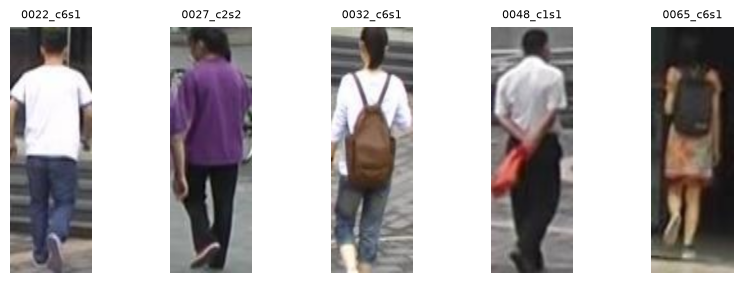

In [5]:
from collections.abc import Callable

import cv2
import matplotlib.pyplot as plt

HEIGHT, WIDTH = INPUT_HW
SAMPLE_PATHS = sorted((FASTREID_DIR / "tools/deploy/test_data").glob("*.jpg"))


def preprocess(images_bgr: list[np.ndarray], height: int = HEIGHT, width: int = WIDTH) -> np.ndarray:
    """Convert BGR images of any size to uint8 RGB crops (the network normalizes them itself).

    :param images_bgr: list of BGR images [h, w, 3]
    :param height: crop height expected by the model
    :param width: crop width expected by the model
    :return: crops [N, 3, height, width]
    """
    return np.stack([cv2.resize(img[:, :, ::-1], dsize=(width, height), interpolation=cv2.INTER_LINEAR).transpose(2, 0, 1) for img in images_bgr])


def embed(infer: Callable[[np.ndarray], np.ndarray], crops: np.ndarray, batch_size: int = BATCH) -> np.ndarray:
    """Compute L2-normalized embeddings from fixed batches of crops (the last batch is zero-padded).

    :param infer: function that maps a batch [batch_size, 3, H, W] to embeddings [batch_size, 2048]
    :param crops: crops [N, 3, H, W]
    :param batch_size: batch size the model was converted for
    :return: embeddings [N, 2048]
    """
    feats = []
    for i in range(0, len(crops), batch_size):
        batch = crops[i : i + batch_size].astype(np.float32)
        n = len(batch)
        if n < batch_size:
            batch = np.concatenate([batch, np.zeros((batch_size - n, *batch.shape[1:]), dtype=np.float32)])
        feats.append(infer(np.ascontiguousarray(batch))[:n])
    feats = np.concatenate(feats)
    return feats / np.maximum(np.linalg.norm(feats, axis=1, keepdims=True), 1e-12)


sample_crops = preprocess(images_bgr=[cv2.imread(str(p)) for p in SAMPLE_PATHS])
fig, axs = plt.subplots(1, len(sample_crops), figsize=(2 * len(sample_crops), 3.2))
for ax, crop, path in zip(axs, sample_crops, SAMPLE_PATHS):
    ax.imshow(crop.transpose(1, 2, 0))
    ax.set_title(path.stem[:9], fontsize=8)  # <person id>_<camera>...
    ax.axis("off")
plt.show()

### Run PyTorch inference
[back to top ⬆️](#Table-of-contents:)

The embeddings of the five crops are the reference for the converted models. To see what an embedding is good for, each crop is also mirrored (the same person in a different view) and used as a *query* against the five originals: the most similar original should be the crop it came from.

In [6]:
def create_pytorch_infer(model: torch.nn.Module) -> Callable[[np.ndarray], np.ndarray]:
    """Create an inference function for a PyTorch model.

    :param model: PyTorch model in eval mode
    :return: function that maps a NumPy batch to a NumPy array of embeddings
    """

    def infer(batch: np.ndarray) -> np.ndarray:
        with torch.inference_mode():
            return model(torch.from_numpy(batch)).numpy()

    return infer


pytorch_infer = create_pytorch_infer(model=pt_model)
raw = pytorch_infer(np.zeros((BATCH, 3, HEIGHT, WIDTH), dtype=np.float32) + 100)
print(f"raw output {raw.shape}, L2 norm {np.linalg.norm(raw, axis=1).mean():.1f} (not normalized)")

pt_embeddings = embed(infer=pytorch_infer, crops=sample_crops)
queries = embed(infer=pytorch_infer, crops=sample_crops[:, :, :, ::-1])  # mirrored crops
similarity = queries @ pt_embeddings.T  # cosine similarity: rows = queries, columns = gallery
print(np.round(similarity, 2))
print("nearest gallery crop for each query:", similarity.argmax(1), "(expected [0 1 2 3 4])")

raw output (8, 2048), L2 norm 30.7 (not normalized)


[[ 0.97 -0.13  0.11  0.22 -0.08]
 [-0.11  0.96 -0.08 -0.04 -0.07]
 [ 0.15 -0.06  0.98  0.06 -0.01]
 [ 0.23 -0.02  0.05  0.97 -0.  ]
 [-0.05 -0.04 -0.02 -0.    0.97]]
nearest gallery crop for each query: [0 1 2 3 4] (expected [0 1 2 3 4])


### Convert model to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR) format. `ov.convert_model` traces the PyTorch module (no ONNX step is needed), and `ov.save_model` serializes the result to `.xml` (topology) and `.bin` (weights). The FP32 IR is created first; the FP16 IR is made from it by compressing the weights to FP16, with inputs and outputs staying `f32`.

In [7]:
import warnings

import openvino as ov

warnings.filterwarnings("ignore", category=FutureWarning)  # torch.jit.trace deprecation notices
core = ov.Core()
IR_DIR = MODEL_DIR / "ir"
fp32_path = IR_DIR / "FP32" / "fast-reid-sbs-r50.xml"
fp16_path = IR_DIR / "FP16" / "fast-reid-sbs-r50.xml"
SHAPE = [BATCH, 3, HEIGHT, WIDTH]

if not fp32_path.exists():
    ov_model = ov.convert_model(input_model=pt_model, example_input=torch.zeros(SHAPE), input=[ov.PartialShape(SHAPE)])
    ov.save_model(model=ov_model, output_model=fp32_path, compress_to_fp16=False)
if not fp16_path.exists():
    ov.save_model(model=core.read_model(fp32_path), output_model=fp16_path, compress_to_fp16=True)

for path in (fp32_path, fp16_path):
    print(f"{path}: {path.with_suffix('.bin').stat().st_size / 1e6:.1f} MB of weights")

model/ir/FP32/fast-reid-sbs-r50.xml: 94.0 MB of weights
model/ir/FP16/fast-reid-sbs-r50.xml: 47.0 MB of weights


### Select inference device
[back to top ⬆️](#Table-of-contents:)

Select device from dropdown list for running inference using OpenVINO

In [8]:
device = device_widget()

device

Dropdown(description='Device:', index=3, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='AUTO')

### Verify model inference
[back to top ⬆️](#Table-of-contents:)

Compile both IRs and compare their embeddings with the PyTorch reference. On GPU an FP32 IR is executed in `f16` unless `f32` is requested, so the FP32 model asks for it explicitly. A correct conversion gives a cosine similarity of ~1.0 with the PyTorch embedding of the same crop.

In [9]:
def create_infer(core: ov.Core, model_path: Path, device_name: str, properties: dict | None = None) -> Callable[[np.ndarray], np.ndarray]:
    """Compile an OpenVINO model and create an inference function for it.

    :param core: OpenVINO Core object
    :param model_path: path to the model ``.xml`` file
    :param device_name: device to compile the model for
    :param properties: optional compile properties
    :return: function that maps a NumPy batch to a NumPy array of embeddings
    """
    request = core.compile_model(model=model_path, device_name=device_name, config=properties or {}).create_infer_request()

    def infer(batch: np.ndarray) -> np.ndarray:
        request.infer({0: batch})
        return request.get_output_tensor(0).data.copy()

    return infer


FP32_PROPERTIES = {} if device.value == "NPU" else {"INFERENCE_PRECISION_HINT": "f32"}
FP32_FLAGS = [] if device.value == "NPU" else ["-infer_precision", "f32"]  # the same request for benchmark_app below

ov_infer = {
    "OpenVINO FP32": create_infer(core=core, model_path=fp32_path, device_name=device.value, properties=FP32_PROPERTIES),
    "OpenVINO FP16": create_infer(core=core, model_path=fp16_path, device_name=device.value),
}
for name, infer in ov_infer.items():
    embeddings = embed(infer=infer, crops=sample_crops)
    cosine = (embeddings * pt_embeddings).sum(1)
    nearest = (embed(infer=infer, crops=sample_crops[:, :, :, ::-1]) @ embeddings.T).argmax(1)
    print(f"{name}: cosine to PyTorch embedding min {cosine.min():.6f} | mirrored-query nearest crop {nearest} (expected [0 1 2 3 4])")

OpenVINO FP32: cosine to PyTorch embedding min 1.000000 | mirrored-query nearest crop [0 1 2 3 4] (expected [0 1 2 3 4])


OpenVINO FP16: cosine to PyTorch embedding min 0.999993 | mirrored-query nearest crop [0 1 2 3 4] (expected [0 1 2 3 4])


### Use the embeddings
[back to top ⬆️](#Table-of-contents:)

The 2048 numbers are an appearance fingerprint, not an identity. Everything is built on one operation: **the cosine similarity of two L2-normalized embeddings** (a dot product, near 1 = looks alike).

- **Search (retrieval):** rank a gallery of crops by similarity to a query crop; the same person should come first (`similarity.argmax` above). Standard metrics are rank-1 and mean average precision (mAP).
- **Verification:** decide "same person or not" with a threshold. The threshold depends on the data and has to be tuned.
- **Tracking:** trackers such as BoT-SORT keep a smoothed embedding per track, embed every detected person and use the cosine distance, together with motion and box overlap, to keep the same ID after occlusions.

ReID models match *appearance*: clothing color, texture and body shape. Two different people in the same outfit can look alike to the model, and the same person after a change of clothes may not.

## Optimize model using NNCF Post-training Quantization API
[back to top ⬆️](#Table-of-contents:)

[NNCF](https://github.com/openvinotoolkit/nncf) provides a suite of advanced algorithms for Neural Networks inference optimization in OpenVINO with minimal accuracy drop.
We will use 8-bit quantization in post-training mode (without the fine-tuning pipeline) to optimize FastReID.

The optimization process contains the following steps:

1. Create a calibration dataset for quantization.
2. Run `nncf.quantize` to obtain a quantized model.
3. Save the INT8 model using the `openvino.save_model` function.

Please select below whether you would like to run quantization to improve model inference speed.

In [10]:
int8_path = IR_DIR / "INT8" / "fast-reid-sbs-r50.xml"

to_quantize = quantization_widget()

to_quantize

Checkbox(value=True, description='Quantization')

Let's load `skip magic` extension to skip quantization if `to_quantize` is not selected

In [11]:
if not Path("skip_kernel_extension.py").exists():
    r = requests.get(
        url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/skip_kernel_extension.py",
    )
    open("skip_kernel_extension.py", "w").write(r.text)

%load_ext skip_kernel_extension

Prepare the calibration dataset for quantization: `nncf.Dataset` wraps a collection of items and a transformation function that turns an item into one model input, here one batch of 8 person crops of shape `[8, 3, 384, 128]`.

For a meaningful INT8 model, calibrate on real person crops. Set `REID_DATA` to a **MOT17** `train` folder (the ground-truth pedestrians of 300 evenly spaced frames from the first half of every sequence are used) or to a **Market-1501** folder (random crops from `bounding_box_train`). Neither dataset can be downloaded automatically. While `REID_DATA` is `None`, the notebook calibrates on mirrored, shifted and re-lit copies of the five public sample crops, so that it runs end to end; the accuracy of that INT8 model is **not** meaningful.

In [12]:
%%skip not $to_quantize.value

from functools import lru_cache, partial

import nncf

REID_DATA = None  # optional: path to a MOT17 "train" folder or to a Market-1501 folder
N_CALIBRATION = 300  # number of calibration batches


def augment(crop: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Mirror, shift/zoom and re-light one crop (used only without real data).

    :param crop: uint8 crop [3, H, W]
    :param rng: random number generator
    :return: augmented float32 crop [3, H, W]
    """
    img = crop.transpose(1, 2, 0)
    if rng.random() < 0.5:
        img = img[:, ::-1]
    h, w = img.shape[:2]
    ch, cw = int(h * rng.uniform(0.85, 1.0)), int(w * rng.uniform(0.85, 1.0))
    y, x = rng.integers(0, h - ch + 1), rng.integers(0, w - cw + 1)
    img = cv2.resize(np.ascontiguousarray(img[y : y + ch, x : x + cw]), dsize=(w, h))
    return np.clip(img.astype(np.float32) * rng.uniform(0.8, 1.2) + rng.uniform(-20, 20), 0, 255).transpose(2, 0, 1)


def sample_batch(seed: int, crops: np.ndarray, batch_size: int = BATCH) -> np.ndarray:
    """Build one calibration batch of augmented sample crops.

    :param seed: seed of the random number generator
    :param crops: sample crops [N, 3, H, W]
    :param batch_size: number of crops in the batch
    :return: float32 batch [batch_size, 3, H, W]
    """
    rng = np.random.default_rng(seed)
    return np.stack([augment(crop=crops[i], rng=rng) for i in rng.integers(0, len(crops), batch_size)]).astype(np.float32)


@lru_cache(maxsize=None)
def load_gt(seq_dir: Path) -> np.ndarray:
    """Load MOT17 ground-truth pedestrians (class 1, considered, visibility >= 0.25).

    :param seq_dir: MOT17 sequence folder
    :return: array with the columns frame, id, x, y, w, h
    """
    gt = np.loadtxt(seq_dir / "gt" / "gt.txt", delimiter=",")
    gt = gt[(gt[:, 6] == 1) & (gt[:, 7] == 1) & (gt[:, 8] >= 0.25)]
    return gt[:, [0, 1, 2, 3, 4, 5]]


def gt_crops(frame_path: Path, height: int = HEIGHT, width: int = WIDTH) -> tuple[np.ndarray, np.ndarray]:
    """Crop the ground-truth pedestrians of one MOT17 frame.

    :param frame_path: path to the frame image
    :param height: crop height expected by the model
    :param width: crop width expected by the model
    :return: crops [N, 3, height, width] and the person ids [N]
    """
    gt = load_gt(seq_dir=frame_path.parent.parent)
    gt = gt[gt[:, 0] == int(frame_path.stem)]
    image = cv2.imread(str(frame_path))
    h, w = image.shape[:2]
    patches = []
    for _, _, x, y, bw, bh in gt:
        x1, y1, x2, y2 = max(0, int(x)), max(0, int(y)), min(w - 1, int(x + bw)), min(h - 1, int(y + bh))
        patches.append(image[y1:y2, x1:x2] if x2 > x1 and y2 > y1 else image[y1 : y1 + 1, x1 : x1 + 1])
    crops = preprocess(images_bgr=patches, height=height, width=width) if patches else np.zeros((0, 3, height, width), dtype=np.uint8)
    return crops, gt[:, 1].astype(int)


def mot17_batch(frame_path: Path, batch_size: int = BATCH) -> np.ndarray:
    """Build one calibration batch from the ground-truth crops of a MOT17 frame.

    :param frame_path: path to the frame image
    :param batch_size: number of crops in the batch
    :return: float32 batch [batch_size, 3, H, W]
    """
    crops = gt_crops(frame_path=frame_path)[0]
    crops = crops[np.random.default_rng(0).permutation(len(crops))[:batch_size]]
    while len(crops) < batch_size:  # a few people only: repeat crops, no zero padding in calibration data
        crops = np.concatenate([crops, crops])[:batch_size]
    return crops.astype(np.float32)


def market_batch(paths: list[Path]) -> np.ndarray:
    """Build one calibration batch from Market-1501 images.

    :param paths: paths of the images in the batch
    :return: float32 batch [len(paths), 3, H, W]
    """
    return preprocess(images_bgr=[cv2.imread(str(p)) for p in paths]).astype(np.float32)


if REID_DATA is None:
    calibration_items, batch_fn = list(range(N_CALIBRATION)), partial(sample_batch, crops=sample_crops)
elif (Path(REID_DATA) / "bounding_box_train").exists():
    files = sorted((Path(REID_DATA) / "bounding_box_train").glob("*.jpg"))
    order = np.random.default_rng(0).permutation(len(files))[: N_CALIBRATION * BATCH]
    calibration_items, batch_fn = [[files[i] for i in order[j : j + BATCH]] for j in range(0, len(order) - BATCH + 1, BATCH)], market_batch  # full batches of 8 only
else:
    frames = []
    for seq_dir in sorted(Path(REID_DATA).glob("MOT17-*-FRCNN")):
        images = sorted((seq_dir / "img1").glob("*.jpg"))
        frames += [p for p in images[: len(images) // 2 + 1] if (load_gt(seq_dir)[:, 0] == int(p.stem)).any()]
    calibration_items, batch_fn = [frames[i] for i in np.linspace(0, len(frames) - 1, N_CALIBRATION).round().astype(int)], mot17_batch

calibration_dataset = nncf.Dataset(data_source=calibration_items, transform_func=batch_fn)
print(f"{len(calibration_items)} calibration batches from", "augmented sample crops" if REID_DATA is None else REID_DATA)

300 calibration batches from augmented sample crops


The `nncf.quantize` function provides an interface for model quantization. It requires an instance of the OpenVINO Model and the quantization dataset. Two groups of operations are kept in float (`ignored_scope`):

- the **GeM pooling and batch-norm neck** (`__module.heads.*`): GeM raises activations to the power 3, a value range that does not survive 8-bit quantization and noticeably distorts the embeddings;
- the stem **`MaxPool`**: it is a pooling with `ceil_mode` that the GPU plugin lowers to a `Pad` with value `-inf`, and a quantized (u8) input makes the GPU plugin fail to compile the model.

The quantized model is saved to disk for the model comparison step.

In [13]:
%%skip not $to_quantize.value

if not int8_path.exists():
    ov_fp32_model = core.read_model(fp32_path)
    float_ops = [op.get_friendly_name() for op in ov_fp32_model.get_ordered_ops() if op.get_type_name() == "MaxPool" or "__module.heads." in op.get_friendly_name()]
    quantized_model = nncf.quantize(
        model=ov_fp32_model,
        calibration_dataset=calibration_dataset,
        subset_size=len(calibration_items),
        fast_bias_correction=True,
        ignored_scope=nncf.IgnoredScope(names=float_ops, validate=False),
    )
    ov.save_model(model=quantized_model, output_model=int8_path)
    print(f"Quantized model saved to {int8_path} ({len(float_ops)} operations kept in float)")

INFO:nncf:6 ignored nodes were found by names in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 6 __module.backbone.maxpool/aten::max_pool2d/MaxPool


INFO:nncf:Not adding activation input quantizer for operation: 263 __module.heads.pool_layer/aten::clamp/Maximum


INFO:nncf:Not adding activation input quantizer for operation: 266 __module.heads.pool_layer/aten::pow/Power


INFO:nncf:Not adding activation input quantizer for operation: 269 __module.heads.pool_layer/aten::adaptive_avg_pool2d/AdaptiveAvgPool


INFO:nncf:Not adding activation input quantizer for operation: 272 __module.heads.pool_layer/aten::pow/Power_1


Output()

Output()

Quantized model saved to model/ir/INT8/fast-reid-sbs-r50.xml (6 operations kept in float)


### Validate Quantized model inference
[back to top ⬆️](#Table-of-contents:)

`nncf.quantize` returns the OpenVINO Model class instance, which is ready to be compiled and used for inference. Compare its embeddings with the PyTorch reference. The cosine similarity is slightly below 1.0, as expected after quantization.

Optionally, set `REID_DATA` to a MOT17 `train` folder to measure ReID accuracy of all three models: for 12 frame pairs per sequence of the *second* half of each sequence (the calibration used the first half), every ground-truth crop in the first frame is ranked against the ground-truth crops 15 frames later. **rank-1** is the share of queries whose best match is the same person, **mAP** the mean average precision.

In [14]:
%%skip not $to_quantize.value

ov_infer["OpenVINO INT8"] = create_infer(core=core, model_path=int8_path, device_name=device.value)
embeddings = embed(infer=ov_infer["OpenVINO INT8"], crops=sample_crops)
cosine = (embeddings * pt_embeddings).sum(1)
nearest = (embed(infer=ov_infer["OpenVINO INT8"], crops=sample_crops[:, :, :, ::-1]) @ embeddings.T).argmax(1)
print(f"OpenVINO INT8: cosine to PyTorch embedding min {cosine.min():.4f}, mean {cosine.mean():.4f} | mirrored-query nearest crop {nearest} (expected [0 1 2 3 4])")


def mot17_accuracy(infer: Callable[[np.ndarray], np.ndarray], mot17_dir: Path, pairs_per_seq: int = 12, gap: int = 15) -> tuple[float, float]:
    """Compute rank-1 and mAP (%) on ground-truth crops of MOT17 frame pairs from the second half of each sequence.

    :param infer: function that maps a batch of crops to embeddings
    :param mot17_dir: MOT17 ``train`` folder
    :param pairs_per_seq: number of query/gallery frame pairs per sequence
    :param gap: distance in frames between the query frame and the gallery frame
    :return: rank-1 and mAP in percent
    """
    rank1, average_precision = [], []
    for seq_dir in sorted(mot17_dir.glob("MOT17-*-FRCNN")):
        images = sorted((seq_dir / "img1").glob("*.jpg"))
        val = images[len(images) // 2 + 1 :]
        for f in np.linspace(0, len(val) - 1 - gap, pairs_per_seq).round().astype(int):
            (query_crops, query_ids), (gallery_crops, gallery_ids) = gt_crops(frame_path=val[f]), gt_crops(frame_path=val[f + gap])
            if len(query_crops) == 0 or len(gallery_crops) == 0:
                continue
            similarity = embed(infer=infer, crops=query_crops) @ embed(infer=infer, crops=gallery_crops).T
            for i, person in enumerate(query_ids):
                if person in gallery_ids:
                    match = gallery_ids[np.argsort(-similarity[i])] == person
                    rank1.append(match[0])
                    average_precision.append(np.mean([(k + 1) / (h + 1) for k, h in enumerate(np.where(match)[0])]))
    return 100 * np.mean(rank1), 100 * np.mean(average_precision)


if REID_DATA is not None and not (Path(REID_DATA) / "bounding_box_train").exists():
    pt_accuracy = mot17_accuracy(infer=pytorch_infer, mot17_dir=Path(REID_DATA))
    print(f"PyTorch FP32: rank-1 {pt_accuracy[0]:.2f}% | mAP {pt_accuracy[1]:.2f}%")
    for name, infer in ov_infer.items():
        rank1, mean_ap = mot17_accuracy(infer=infer, mot17_dir=Path(REID_DATA))
        print(f"{name}: rank-1 {rank1:.2f}% | mAP {mean_ap:.2f}%")
else:
    print("Accuracy is skipped: it needs a MOT17 train folder in REID_DATA (a Market-1501 folder is used for calibration only).")

OpenVINO INT8: cosine to PyTorch embedding min 0.9968, mean 0.9976 | mirrored-query nearest crop [0 1 2 3 4] (expected [0 1 2 3 4])
Accuracy is skipped: it needs a MOT17 train folder in REID_DATA (a Market-1501 folder is used for calibration only).


## Compare Performance of the Models
[back to top ⬆️](#Table-of-contents:)

### Compare performance of the FP32, FP16 and INT8 models
[back to top ⬆️](#Table-of-contents:)

Finally, use the OpenVINO [Benchmark Tool](https://docs.openvino.ai/2025/get-started/learn-openvino/openvino-samples/benchmark-tool.html) to measure the inference performance of the models for a batch of 8 crops. Each model is run twice: with the synchronous API and `-hint latency` for the **average latency** of one request, and with `-hint tput` for the **throughput** (benchmark_app chooses the asynchronous API and the number of parallel requests). `-b 8` makes the reported throughput count crops per second. The FP32 model also requests `f32` execution; otherwise the GPU would silently run it in `f16`.

> **Note**: For more accurate performance, it is recommended to run `benchmark_app` in a terminal/command prompt after closing other applications. Run `benchmark_app -m <model_path> -d CPU -shape '[8,3,384,128]'` to benchmark async inference on CPU for one minute. Change `CPU` to `GPU` to benchmark on GPU.

In [15]:
device

Dropdown(description='Device:', index=3, options=('CPU', 'GPU', 'NPU', 'AUTO'), value='AUTO')

In [16]:
import subprocess


def run_benchmark(model_path: Path, device_name: str, shape: list[int], hint: str, extra_args: list[str] | None = None, duration: int = 15) -> None:
    """Run ``benchmark_app`` and print the number of iterations, the average latency and the throughput.

    :param model_path: path to the model ``.xml`` file
    :param device_name: device to benchmark
    :param shape: input shape, the first dimension is the batch size
    :param hint: ``latency`` (synchronous API) or ``tput`` (asynchronous API, number of requests chosen by benchmark_app)
    :param extra_args: additional ``benchmark_app`` arguments
    :param duration: benchmark duration in seconds
    """
    command = ["benchmark_app", "-m", str(model_path), "-d", device_name, "-b", str(shape[0]), "-shape", f"[{','.join(map(str, shape))}]", "-ip", "f32"]
    command += [*(extra_args or []), "-hint", hint, "-t", str(duration)]
    if hint == "latency":
        command += ["-api", "sync"]
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-2000:], result.stderr[-2000:])
    for line in result.stdout.splitlines():
        if any(key in line for key in ("Count", "Average", "Throughput", "Start inference")):
            print(line)


# Inference FP32 model (OpenVINO IR)
for hint in ("latency", "tput"):
    run_benchmark(model_path=fp32_path, device_name=device.value, shape=SHAPE, hint=hint, extra_args=FP32_FLAGS)

[Step 10/11] Measuring performance (Start inference synchronously, limits: 15000 ms duration)
[ INFO ] Count:            2086 iterations
[ INFO ]    Average:       7.14 ms
[ INFO ] Throughput:   1112.38 FPS


[Step 10/11] Measuring performance (Start inference asynchronously, 4 inference requests, limits: 15000 ms duration)
[ INFO ] Count:            1820 iterations
[ INFO ]    Average:       32.82 ms
[ INFO ] Throughput:   968.96 FPS


In [17]:
# Inference FP16 model (OpenVINO IR)
for hint in ("latency", "tput"):
    run_benchmark(model_path=fp16_path, device_name=device.value, shape=SHAPE, hint=hint)

[Step 10/11] Measuring performance (Start inference synchronously, limits: 15000 ms duration)
[ INFO ] Count:            2297 iterations
[ INFO ]    Average:       6.48 ms
[ INFO ] Throughput:   1224.89 FPS


[Step 10/11] Measuring performance (Start inference asynchronously, 4 inference requests, limits: 15000 ms duration)
[ INFO ] Count:            1788 iterations
[ INFO ]    Average:       33.45 ms
[ INFO ] Throughput:   952.33 FPS


In [18]:
if int8_path.exists():
    # Inference INT8 model (OpenVINO IR)
    for hint in ("latency", "tput"):
        run_benchmark(model_path=int8_path, device_name=device.value, shape=SHAPE, hint=hint)

[Step 10/11] Measuring performance (Start inference synchronously, limits: 15000 ms duration)
[ INFO ] Count:            3099 iterations
[ INFO ]    Average:       4.78 ms
[ INFO ] Throughput:   1652.68 FPS


[Step 10/11] Measuring performance (Start inference asynchronously, 4 inference requests, limits: 15000 ms duration)
[ INFO ] Count:            2948 iterations
[ INFO ]    Average:       20.28 ms
[ INFO ] Throughput:   1570.09 FPS


In [19]:
# Uncomment the lines below to remove the downloaded FastReID code and checkpoint and the converted models.
# import shutil

# shutil.rmtree(MODEL_DIR)